In [1]:
import pandas as pd
df = pd.read_csv('../1.9 Bike Sharing/data/day.csv')
print(df.shape)
df.info()
assert df.shape[0] == 731

(731, 16)
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB


In [2]:
df["dteday"] = pd.to_datetime(df["dteday"])
df.info()
print(df["dteday"].min())
print(df["dteday"].max())

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), float64(4), int

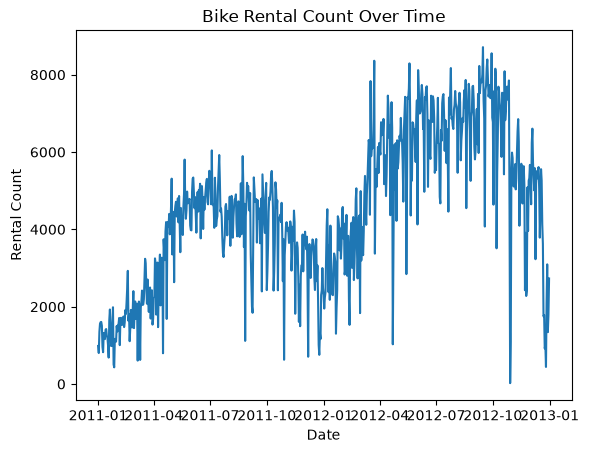

In [3]:
import matplotlib.pyplot as plt
plt.plot(df["dteday"], df["cnt"])
plt.title("Bike Rental Count Over Time")
plt.xlabel("Date")
plt.ylabel("Rental Count")
plt.savefig("figure1_daily_demand.png", dpi=150, bbox_inches="tight")
plt.show()


In [4]:
weather_avg = df.groupby("weathersit")["cnt"].mean()
print(weather_avg)

weathersit
1    4876.786177
2    4035.862348
3    1803.285714
Name: cnt, dtype: float64


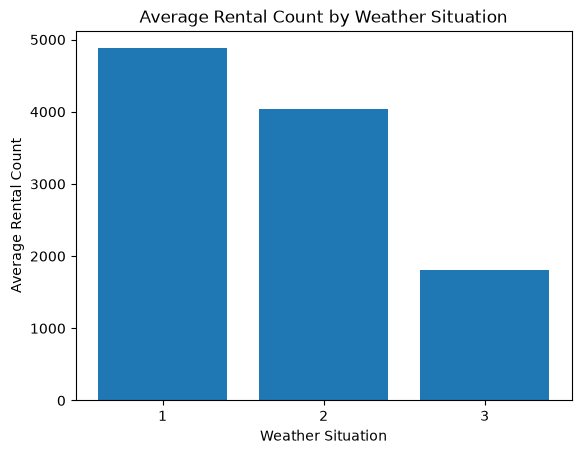

In [5]:
plt.bar(weather_avg.index, weather_avg.values)
plt.xlabel("Weather Situation")
plt.ylabel("Average Rental Count")
plt.title("Average Rental Count by Weather Situation")
plt.xticks(weather_avg.index)
plt.savefig("figure2_daily_demand.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
weather_counts = df.groupby("weathersit")["cnt"].count()
print(weather_counts)

weathersit
1    463
2    247
3     21
Name: cnt, dtype: int64


In [7]:
monthly_avg = df.groupby(["yr", "mnth"])["cnt"].mean()
print(monthly_avg)

yr  mnth
0   1       1231.903226
    2       1721.964286
    3       2065.967742
    4       3162.333333
    5       4381.322581
    6       4783.733333
    7       4559.387097
    8       4409.387097
    9       4247.266667
    10      3984.225806
    11      3405.566667
    12      2816.870968
1   1       3120.774194
    2       3556.448276
    3       5318.548387
    4       5807.466667
    5       6318.225806
    6       6761.000000
    7       6567.967742
    8       6919.451613
    9       7285.766667
    10      6414.225806
    11      5088.800000
    12      3990.741935
Name: cnt, dtype: float64


In [8]:
monthly_pivot = monthly_avg.unstack("yr")
print(monthly_pivot)
print(monthly_pivot.shape)

yr              0            1
mnth                          
1     1231.903226  3120.774194
2     1721.964286  3556.448276
3     2065.967742  5318.548387
4     3162.333333  5807.466667
5     4381.322581  6318.225806
6     4783.733333  6761.000000
7     4559.387097  6567.967742
8     4409.387097  6919.451613
9     4247.266667  7285.766667
10    3984.225806  6414.225806
11    3405.566667  5088.800000
12    2816.870968  3990.741935
(12, 2)


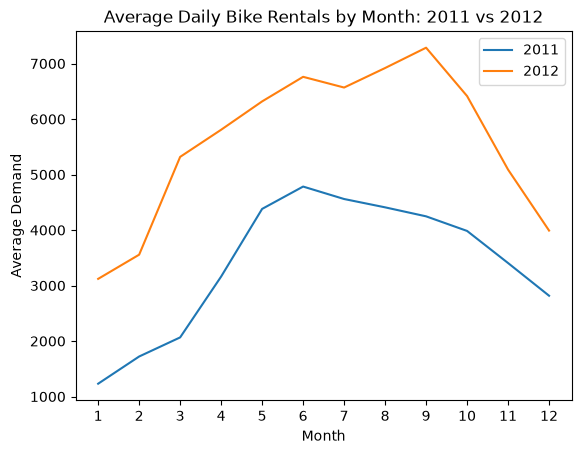

In [9]:
plt.plot(monthly_pivot.index, monthly_pivot[0], label="2011")
plt.plot(monthly_pivot.index, monthly_pivot[1], label="2012")
plt.xlabel("Month")
plt.ylabel("Average Demand")
plt.title("Average Daily Bike Rentals by Month: 2011 vs 2012")
plt.xticks(monthly_pivot.index)
plt.legend()
plt.savefig("figure3_monthly_demand.png", dpi=150, bbox_inches="tight")
plt.show()

## Prediction Target and Feature Availability
Feature	Available at prediction time?	Use as input?	Reason
mnth	Yes	Yes	will be available at prediction time
yr	Yes	Yes	will be available at prediction time
weathersit (actual observed weather)	no	no	won't be available at prediction time
casual	no	no	won't be available at prediction time
registered	no	no	won't be available at prediction time

## Prediction Target and Feature Availability

### Prediction Target

Our goal is to build a supervised machine learning model that predicts **tomorrow's total daily bike rentals (`cnt`) at 6 PM today**.

The model will use information available at prediction time to estimate the total number of rentals for the following day.

### Feature Availability and Target Leakage

| Feature | Available at Prediction Time? | Use as Input? | Reason |
|---|---|---|---|
| `mnth` | Yes | Yes | The month is known in advance and may help the model identify seasonal demand patterns. |
| `yr` | Yes | Yes, with caution | The year is known in advance and may help represent long-term trends. However, the model may struggle to generalize to years outside the training dataset. |
| `weathersit` (actual observed weather) | No | No | Tomorrow's actual weather conditions are unknown at prediction time. Historical weather forecasts could be used instead, if available. |
| `casual` | No | No | Tomorrow's casual rental count is unknown. It is also part of the target variable. |
| `registered` | No | No | Tomorrow's registered rental count is unknown. It is also part of the target variable. |

### Target Leakage Risks

Target leakage occurs when a model uses information that would not be available when making predictions in the real world.

In this dataset:

- `casual` and `registered` must be excluded because their sum equals `cnt`, the target variable.
- Actual observed weather for tomorrow must be excluded because it is not available when predicting at 6 PM today.
- Calendar features such as `mnth` and `yr` do not cause target leakage because they are known in advance.

### Why Target Leakage Is Dangerous

If a model uses `casual` and `registered` to predict `cnt`, it could achieve nearly perfect accuracy because:

**`casual + registered = cnt`**

However, this performance would be misleading because neither count is available when predicting tomorrow's rentals.

The model would perform well during evaluation using leaked information but could fail in production, where that information is unavailable.

### Conclusion

A reliable machine learning model must use features that are available at the time predictions are made. High evaluation accuracy is not meaningful if the model depends on future information that would be unavailable in real-world deployment.

In [10]:
assert (df["casual"] + df["registered"] == df["cnt"]).all()